# Hälsostudien

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

df = pd.read_csv("health_study_dataset.csv")

In [2]:
from functions_in_modules import DataInvestigator

investigator = DataInvestigator(df)

investigator.show_duplicates()
print("---" * 14)
investigator.show_info()


Inga dubletter hittades.
------------------------------------------
<class 'pandas.DataFrame'>
RangeIndex: 800 entries, 0 to 799
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   id           800 non-null    int64  
 1   age          800 non-null    int64  
 2   sex          800 non-null    str    
 3   height       800 non-null    float64
 4   weight       800 non-null    float64
 5   systolic_bp  800 non-null    float64
 6   cholesterol  800 non-null    float64
 7   smoker       800 non-null    str    
 8   disease      800 non-null    int64  
dtypes: float64(4), int64(3), str(2)
memory usage: 56.4 KB


In [3]:
investigator.show_describe()

health_data = investigator.health_stats([
    "age",
    "weight",
    "height",
    "systolic_bp",
    "cholesterol"
])

print(health_data)

             id         age      height      weight  systolic_bp  cholesterol  \
count  800.0000  800.000000  800.000000  800.000000   800.000000   800.000000   
mean   400.5000   49.426250  171.849250   73.413000   149.178625     4.929150   
std    231.0844   14.501118    9.804259   13.685059    12.793360     0.848413   
min      1.0000   18.000000  144.400000   33.700000   106.800000     2.500000   
25%    200.7500   39.000000  164.775000   64.800000   140.900000     4.327500   
50%    400.5000   50.000000  171.350000   73.200000   149.400000     4.970000   
75%    600.2500   59.000000  178.925000   82.600000   157.600000     5.482500   
max    800.0000   90.000000  200.400000  114.400000   185.900000     7.880000   

          disease  
count  800.000000  
mean     0.058750  
std      0.235303  
min      0.000000  
25%      0.000000  
50%      0.000000  
75%      0.000000  
max      1.000000  
                   mean  median    min     max
age           49.426250   50.00   18.0   90

In [4]:
investigator.show_head(10) 


=== HEAD ===
   id  age sex  height  weight  systolic_bp  cholesterol smoker  disease
0   1   57   F   168.9    65.8        141.8         4.58     No        0
1   2   47   M   180.4    95.9        144.8         5.18    Yes        0
2   3   59   F   169.9    82.2        151.7         6.16     No        0
3   4   72   M   157.7    93.1        151.0         6.63     No        0
4   5   46   M   192.6   104.1        144.1         5.21     No        0
5   6   46   F   167.6    68.6        153.8         4.91     No        0
6   7   73   M   185.8    83.0        150.0         5.92     No        0
7   8   61   F   168.1    51.5        134.8         5.13    Yes        0
8   9   42   M   182.3    81.7        141.0         4.02     No        0
9  10   58   F   157.1    67.3        159.8         5.38     No        0


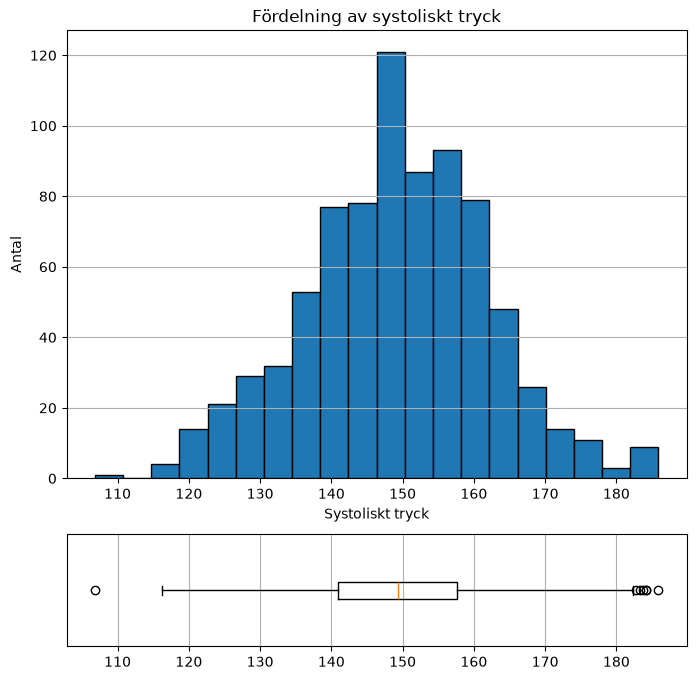

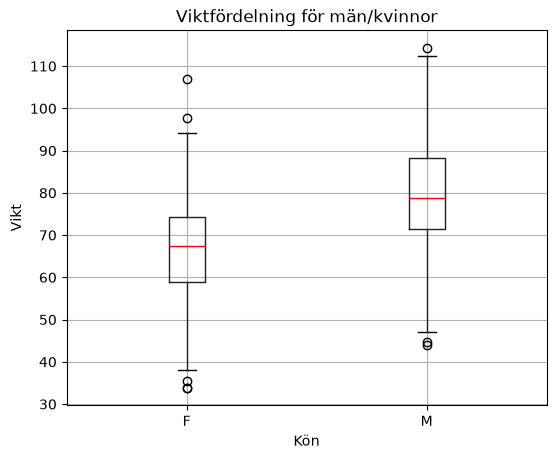

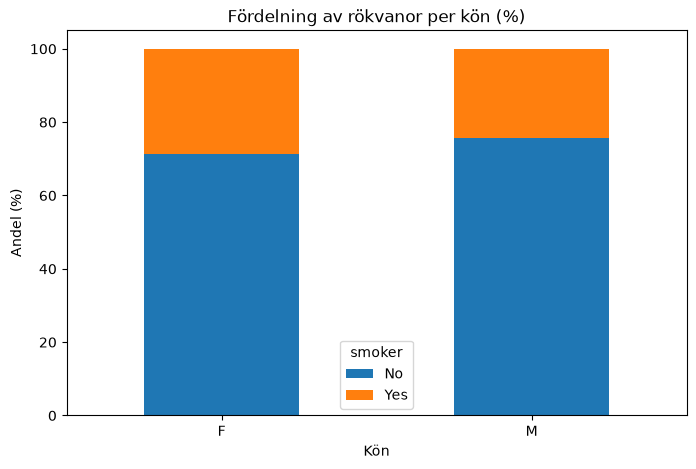

<Figure size 640x480 with 0 Axes>

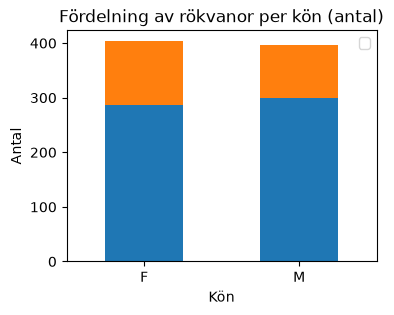

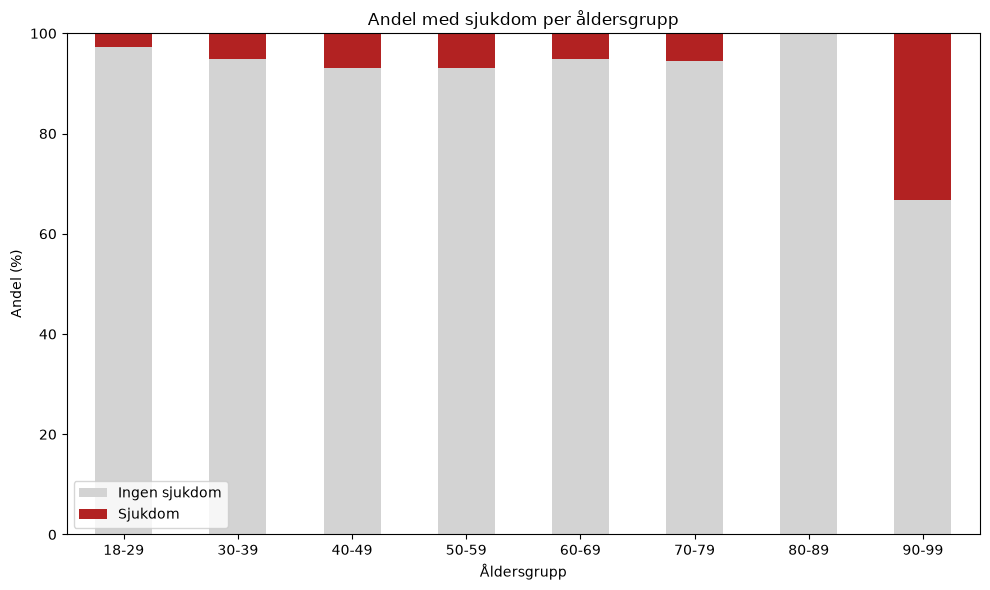

<Figure size 1000x600 with 0 Axes>

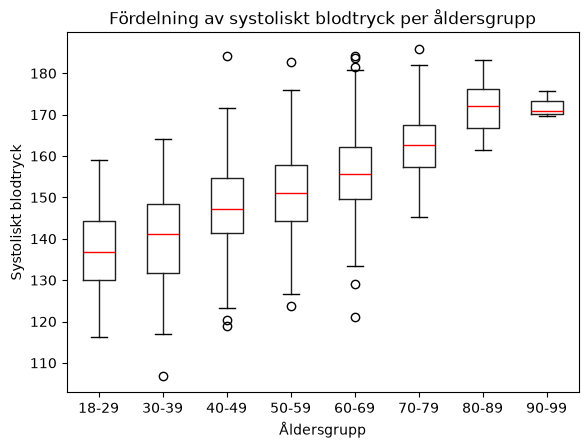

In [5]:
### Visualiseringar av inital analys

# Histogram + boxplot över systoliskt tryck:

fig, (ax_hist, ax_box) = plt.subplots(2, 1, figsize=(8, 8), gridspec_kw={"height_ratios":[4,1]})

ax_hist.hist(df["systolic_bp"], bins=20, edgecolor="black")
ax_hist.set_title("Fördelning av systoliskt tryck")
ax_hist.set_xlabel("Systoliskt tryck")
ax_hist.set_ylabel("Antal")
ax_hist.grid(axis="y")

ax_box.boxplot(df["systolic_bp"], orientation="horizontal")
ax_box.set_yticks([]) 
ax_box.grid(axis="x")


# Boxplot över viktfördelning inom grupperna män/kvinnor:

fig, ax = plt.subplots(figsize=(6, 5))
df.boxplot(column="weight", by="sex", medianprops={'color': 'red', 'linewidth': 1}, ax=ax)
ax.set_title("Viktfördelning för män/kvinnor")
ax.set_xlabel("Kön")
ax.set_ylabel("Vikt")
plt.suptitle("")

# Stapeldiagram över rökvanor, uppdelat på män/kvinnor (%):

count_smokers = df.groupby(["sex", "smoker"]).size().unstack()
perc_smokers = count_smokers.div(count_smokers.sum(axis=1), axis=0) * 100

perc_smokers.plot(kind="bar", stacked=True, figsize=(8,5))
plt.xlabel("Kön")
plt.ylabel("Andel (%)")
plt.title("Fördelning av rökvanor per kön (%)")
plt.xticks(rotation=0)
plt.show()

plt.tight_layout()

# Stapeldiagram över antalet rökare fördelat på kön:

count_smokers.plot(kind="bar", stacked=True, figsize=(4, 3))
plt.xlabel("Kön")
plt.ylabel("Antal")
plt.title("Fördelning av rökvanor per kön (antal)")
plt.xticks(rotation=0)
plt.legend([])
plt.show()


# Fördelning av sjuka/icke sjuka med avseende på ålder:

# Åldersgruppering
bins = [18, 30, 40, 50, 60, 70, 80, 90, 100]
labels = ["18-29", "30-39", "40-49", "50-59",
          "60-69", "70-79", "80-89", "90-99"]

df["age_group"] = pd.cut(
    df["age"],
    bins=bins,
    labels=labels,
    right=False
)

# Räknar ut antal i varje kombination av åldersgrupp-sjukdom
count = (
    df.groupby(["age_group", "disease"])
      .size()
      .unstack(fill_value=0)
)

# Omvandlar till procent inom varje åldersgrupp
perc = count.div(count.sum(axis=1), axis=0) * 100

perc.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 6),
    color=["lightgray", "firebrick"]
)

plt.xlabel("Åldersgrupp")
plt.ylabel("Andel (%)")
plt.title("Andel med sjukdom per åldersgrupp")
plt.xticks(rotation=0)
plt.legend(["Ingen sjukdom", "Sjukdom"], loc="lower left")
plt.tight_layout()
plt.show()


# Del2 - Fördelning av blodtryck med avseende på ålder:

plt.figure(figsize=(10, 6))

df.boxplot(
    column="systolic_bp",
    by="age_group",
    grid=False,
    medianprops={'color': 'red', 'linewidth': 1}
)

plt.title("Fördelning av systoliskt blodtryck per åldersgrupp")
plt.suptitle("")
plt.xlabel("Åldersgrupp")
plt.ylabel("Systoliskt blodtryck")
plt.show()


Utifrån figurerna finns ett par saker att kommentera:

- Prevalensen av rökning är hög i det här materialet, högre än i en svensk population.
- Prevalensen för sjukdom är högst i den översta åldersgruppen, vilket för "sjukdom som fenomen" är normalt, de flesta sjukdomar ökar i förekomst med ökande ålder. I det näst högsta åldersspannet finns ingen med sjukdom. Detta kan ju i teorin betyda, beroende på vilken sjukdom det är, att de som hade sjukdomen har gått bort eller att det av en slump inte finns några sjuka där om tex gruppen i sig är en mindre andel. 
- Fördelningen av systoliskt blodtryck per åldersgrupp visar att, i jämförelse med hela populationen i Sverige, ligger alla åldersgrupper högt i det här materialet. Framförallt reagerar man på de yngsta, 18-29 och 30-39, vars interkvartilavstånd ligger helt över 130. 

In [6]:
# Jämförelse befintlig data med simulerade personer:

real_dis = df["disease"].mean()

np.random.seed(42)

simu_age = np.random.randint(18, 100, size=1000)
simu_sex = np.random.choice(["M", "F"], size=1000)
simu_height = np.random.normal(loc=170, scale=15, size=1000)
simu_weight = np.random.normal(loc=75, scale=15, size=1000)
simu_bp = np.random.normal(loc=125, scale=15, size=1000)
simu_chol = np.random.normal(loc=5.2, scale=1.0, size=1000)
simu_smoker = np.random.choice(["Yes", "No"], p=[0.25, 0.75], size=1000)
simu_dis = np.random.binomial(n=1, p=real_dis, size=1000)

simu_df = pd.DataFrame({
    "age": simu_age,
    "sex": simu_sex,
    "height": simu_height,
    "weight": simu_weight,
    "systolic_bp": simu_bp,
    "cholesterol": simu_chol,
    "smoker": simu_smoker,
    "disease": simu_dis
})

# simu_df.head(15)

print(f'Prevalens av sjukdom i den verkliga datan: {real_dis:.3f} ({real_dis * 100:.1f}%)')
print(f'Prevalens av sjukdom i den syntetiska datan: {simu_dis.mean():.3f} ({simu_dis.mean() * 100:.1f}%)')

Prevalens av sjukdom i den verkliga datan: 0.059 (5.9%)
Prevalens av sjukdom i den syntetiska datan: 0.046 (4.6%)


- Sjukdomsprevalensen i grupperna är ganska lika, vilket är förväntat eftersom sjukdomsmedelvärdet från ursprungsdatan användes som underlag till att slumpa den synetetiska datans sjukdomsprevalens. 
- Det viktiga totalt sett är att jämförelsen baseras på att den syntetiska datan har samma sjukdomsprevalens som den ursprungliga datan, men i övrigt kan inga slutsatser om samband mellan olika riskfaktorer dras. En 19-årig frisk icke-rökare skulle kunna ha samma risk för sjukdom som en 92-årig rökare med högt blodtryck och högt kolesterol eftersom någon sådan "logisk skillnad" inte har gjorts i urvalet sjuk/icke sjuk, men i ursprungsdatan kan ett sådant samband finnas.  
- Och ja, det var onödigt att göra en dataframe med ett helt dataset motsvarande ursprunget, det inser jag i efterhand. Men jag fick träna på det i alla fall. Jag fastnade nog i tanken om att alla ingående faktorer behövde finnas, vilket de förstås inte behöver. Det hade räckt med ett slumpat urval på "disease". 

# Konfidensintervall och hypotesprövning

In [7]:
# Konfidensintervall för medelvärdet av systoliskt tryck, med hjälp av Bootstrap:

bp = df["systolic_bp"]

bootstrap_means = []

for _ in range(5000):
    sample = np.random.choice(bp, size=len(bp), replace=True)
    bootstrap_means.append(sample.mean())

ci_boot_low = np.percentile(bootstrap_means, 2.5)
ci_boot_high = np.percentile(bootstrap_means, 97.5)


# Konfidensintervall för medelvärdet av systoliskt tryck, med hjälp av Normalmetoden:

m = bp.mean()
s = bp.std(ddof=1)
se = s / np.sqrt(len(bp))

ci_norm_low = m - 1.96 * se
ci_norm_high = m + 1.96 * se

# Sammanfattande utskrift:

print(f'Medelvärdet för systoliskt tryck: {health_data.loc["systolic_bp", "mean"]:.2f}')
print(f'95% CI (metod: Bootstrap): [{ci_boot_low:.2f}, {ci_boot_high:.2f}]')
print(f'95% CI (metod: Normalapproximation): [{ci_norm_low:.2f}, {ci_norm_high:.2f}]')

Medelvärdet för systoliskt tryck: 149.18
95% CI (metod: Bootstrap): [148.31, 150.07]
95% CI (metod: Normalapproximation): [148.29, 150.07]


- Resultaten av de båda metoderna är mycket lika.
- Likheten är förväntad utifrån att materialet är "medelstort" och ingen uppenbar snedfördelning finns, därmed fungerar båda metoderna bra.
- Helhetsbedömningen blir att skattningen troligen är god för vad konfidensintervallet faktiskt är. 

In [8]:
# Hypotesprövning

# Hypotes: "Rökare har högre medel-blodtryck än icke-rökare"
# Detta är en ensidig hypotesprövning för att undersöka om medelvärdet (gällande blodtryck) för rökare är högre än det för icke-rökare (alternativhypotes).
# Nollhypotes är därmed: "Det är ingen skillnad mellan blodtrycket för rökare och icke-rökare".

bp_smokers = df[df["smoker"] == "Yes"]["systolic_bp"]
bp_nonsmokers = df[df["smoker"] == "No"]["systolic_bp"]

obs_diff = bp_smokers.mean() - bp_nonsmokers.mean()
print(f'Observerad skillnad: {obs_diff:.2f}')

# Bootstrap-test:

boot_diffs = []

for _ in range(5000):
    boot_smokers = np.random.choice(bp_smokers, size=len(bp_smokers), replace=True)
    boot_nonsmokers = np.random.choice(bp_nonsmokers, size=len(bp_nonsmokers), replace=True)
    boot_diffs.append(boot_smokers.mean() - boot_nonsmokers.mean())

boot_diffs = np.array(boot_diffs)

# p-värde:
# Svarar på frågan hur stor andel av bootstrap‑skillnaderna från listan boot_diffs som är lika stora eller större än den observerade skillnaden.

p_value = np.mean(boot_diffs >= obs_diff)
print(f'p-värde (metod: Bootstrap): {p_value:.3f}')


Observerad skillnad: 0.47
p-värde (metod: Bootstrap): 0.505


### Slutsatser av hypotesprövningen 
- p-värdet blir ganska högt vilket innebär att nollhypotesen inte kan förkastas.
- Slumpen ger ofta, i det här materialet, en lika stor eller större skillnad än den vi såg i vårt dataset. 
- Sammanfattningsvis innebär resultatet att i vårt material finns det inte stöd för att hävda att rökare verkligen har högre blodtryck än icke-rökare. 
- Gällande metodval hade både Welchs t-test och Bootstrap-test varit lämpliga alternativ eftersom stickprovet omfattade cirka 800 personer. Jag valde Bootstrap-testet och den metoden bygger direkt på den observerade datan och kräver färre antaganden om dess fördelning, enligt vårt kursinnehåll. 
- Bootstrap passade också ihop med mitt förstahandsval när jag räknade ut konfidensintervall (även om jag använde båda metoderna där då det ingick i uppgiften).

In [9]:
# Power som en efterhands-analys av hur "stark" bedömningen var. 
# (Till skillnad från en powerberäkning i förväg där beräkningen hjälper till att bedöma hur stora urvalsstorlekar som behövs för en studie.)

# Börjar med att ta fram effektstorleken, dvs Cohen's d:

from statsmodels.stats.power import TTestIndPower

# Observerad skillnad
mean_diff = bp_smokers.mean() - bp_nonsmokers.mean()

# Poolad standardavvikelse
# Ger oss ett mått på spridningen kring medelvärdet för respektive grupps värden.
sd_pooled = np.sqrt((bp_smokers.var(ddof=1) + bp_nonsmokers.var(ddof=1)) / 2)

# Cohen's d
effect_size = abs(mean_diff / sd_pooled)

print(f'Skillnad i medelvärde: {mean_diff:.2f}')
print(f'Poolad standardavvikelse: {sd_pooled:.2f}')
print(f'Cohens d: {effect_size:.3f}')

# Med hjälp av effektstorleken kan power beräknas:
analysis = TTestIndPower()

power = analysis.power(
    effect_size=effect_size,
    nobs1=len(bp_smokers),
    ratio=len(bp_nonsmokers) / len(bp_smokers),
    alpha=0.05
)

print(f'Power i det befintliga testet: {power * 100:.1f}%')

Skillnad i medelvärde: 0.47
Poolad standardavvikelse: 12.95
Cohens d: 0.036
Power i det befintliga testet: 7.4%


In [10]:
# En teoretisk simulering av power, utifrån det ursprungliga datasetets gruppstorlekar, medelvärden och spridning:
# rejections räknar hur många gånger vi förkastar nollhypotesen, dvs när vår simulering upptäcker p <= 0.05

from scipy import stats
np.random.seed(42) 

S = df.loc[df["smoker"] == "Yes", "systolic_bp"]    
non_S = df.loc[df["smoker"] == "No", "systolic_bp"]     
mean_S = S.mean()                          
mean_non_S = non_S.mean()                          
min_detectable_diff = mean_S - mean_non_S      
alpha = 0.05                               

n_sims = 10000
rejections = 0       

for _ in range(n_sims):  

    S_sim = np.random.normal(mean_S, S.std(), len(S))
    non_S_sim = np.random.normal(mean_non_S, non_S.std(), len(non_S))

    # Tvåsidigt Welch t-test:
    _, p_val = stats.ttest_ind(S_sim, non_S_sim, equal_var=False, alternative="two-sided")

    rejections += (p_val < alpha) 

sim_power = rejections / n_sims     
print(f"Simulerad Power: {sim_power * 100:.1f}%")

Simulerad Power: 6.7%


### Min tolkning av poweranalysen:

- När jag först räknad fram power i det befintliga testet blev jag förvånad över hur låg den var. När jag sedan började titta närmare på respektive del i uträkningen av powern insåg jag:
- Till att börja med är det en mycket liten skillnad i medelvärde (blodtryck) mellan rökare och icke-rökare i det här materialet.
- Detta kommer i sin tur att innebära att effektstorleken blir väldigt liten (0.036). 
- En så liten effekt är svår att upptäcka från första början och skulle antagligen kräva betydligt större material än vårt för att "synas", om det är en verklig skillnad. 
- Effektstorleken ligger i sin tur till grund för själva powerberäkningen vars resultat därmed blir lågt --> bara 7,4%.
- De 10000 simuleringarna av powern utifrån det befintliga datasetets spridning, observerad skillnad och stickprovsstorlek resulterar i power 6,7% ungefär vilket styrker det ursprungliga resultatet.
- Alltså, om den sanna effekten av rökning på blodtryck är lika liten som den vi såg i det här materialet, så har testet ungefär 6-7% sannolikhet att upptäcka skillnaden (vid alpha = 0.05).

In [11]:
required_n = analysis.solve_power(effect_size=effect_size, power=0.80, alpha=0.05)

required_n_rounded = int(np.ceil(required_n))

print(f'Antalet behövda personer per grupp (rökare/icke rökare): {required_n_rounded}')
print(f'Antal rökare i materialet: {len(bp_smokers)}')
print(f'Antal icke-rökare i materialet: {len(bp_nonsmokers)}')

Antalet behövda personer per grupp (rökare/icke rökare): 11825
Antal rökare i materialet: 213
Antal icke-rökare i materialet: 587


### Skattning av antalet behövda personer per grupp
- Skattning av hur många personer varje grupp skulle behöva innehålla för att ha en chans att upptäcka en faktisk skillnad gällande en så liten medelvärdesskillnad som 0.47 enheter mellan de två grupperna rökare och icke-rökare. 
- Om detta relateras till populationsnivå skulle egentligen bara en stor befolkningsstudie kunna upptäcka en verklig skillnad, givet att förekomsten av rökning skulle vara så hög (typ 25%) som den är i vårt material. 
- I verkligheten klassas Sverige numera som ett rökfritt land (andelen rökare < 5%) och det är därför praktiskt utmanande att få ihop en så stor grupp med rökare idag. 

# Regressionsanalys

- Nedan följer två varianter av enkel regressionsmodell för systoliskt blodtryck mot ålder respektive vikt. 
- Därefter en multipel regression för systoliskt tryck med prediktorer ålder, vikt, kolesterol och rökning (som numeriskt värde 0/1)
- Avslutningsvis en figur som visar träffsäkerhet för hur väl den multipla regressionen motsvarar det faktiska utfallet i vår data. 

{'predictor': 'age', 'intercept': np.float64(122.68488970435858), 'slope': np.float64(0.5360255996690306), 'R2': 0.36915159840526035}


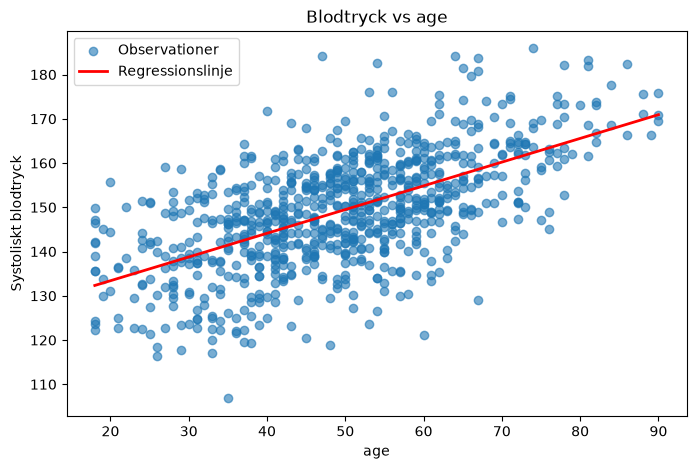

In [12]:
# Tränar en enkel regressionmodell på sambandet systoliskt tryck som utfallsvariabel och ålder som prediktor

from sklearn.linear_model import LinearRegression
from bp_class import BloodPressureInvestigator

bp_investigator = BloodPressureInvestigator(df)

bp_vs_age = bp_investigator.simple_regression("age")

print(bp_vs_age)

bp_investigator.plot_regression("age")


- Tolkningen av analysen och denna figur är att det finns ett positivt linjärt samband för ökande ålder och högre systoliskt tryck.
- Det finns dock en stor spridning runt linjen vilket tyder på att faktorn ålder ensam inte kan förklara blodtrycksökningen.

{'predictor': 'weight', 'intercept': np.float64(136.86191098088477), 'slope': np.float64(0.16777292876078118), 'R2': 0.03220830266433383}


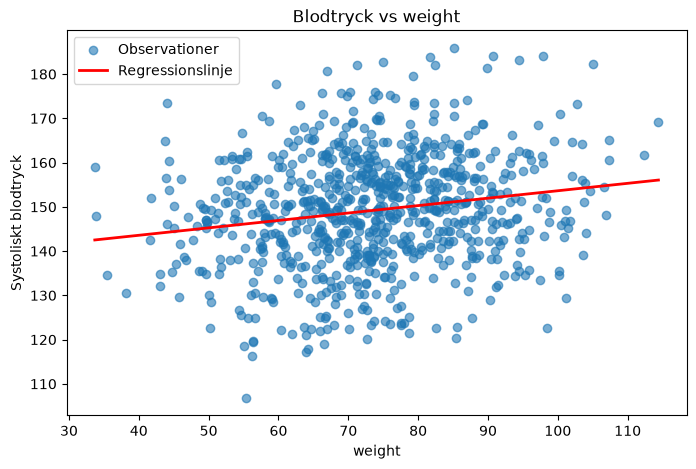

In [13]:
# Enkel regressionsmodell på sambandet systoliskt tryck som utfallsvariabel och vikt som prediktor

bp_vs_weight = bp_investigator.simple_regression("weight")

print(bp_vs_weight)

bp_investigator.plot_regression("weight")

- Tolkningen av analysen och denna figur är att det finns ett mycket svagt positivt linjärt samband för ökande vikt och högre systoliskt tryck.
- Dock, spridningen runt linjen här är mycket stor och R2 är bara 3% vilket sammantaget ger lågt stöd för att förklara blodtrycksökning med högre vikt. 

In [14]:
# Multipel regression för systoliskt tryck som utfallsvariabel och prediktorer: ålder, vikt, kolesterol och rökning
# En ytterligare kolumn adderas till dataframen, för att kunna använda rökare/icke rökare som numeriskt värde.

df["smoker_num"] = df["smoker"].map({"No": 0, "Yes": 1})

bp_investigator.multiple_regression(["age", "weight", "cholesterol", "smoker_num"])

bp_investigator.print_summary()




--- Sammanfattning av regressionsanalys ---
Prediktorer: age | weight | cholesterol | smoker_num
Intercept: 108.575

Koefficienter:
age          0.527
weight       0.171
cholesterol  0.428
smoker_num   -0.362

R2: 0.406


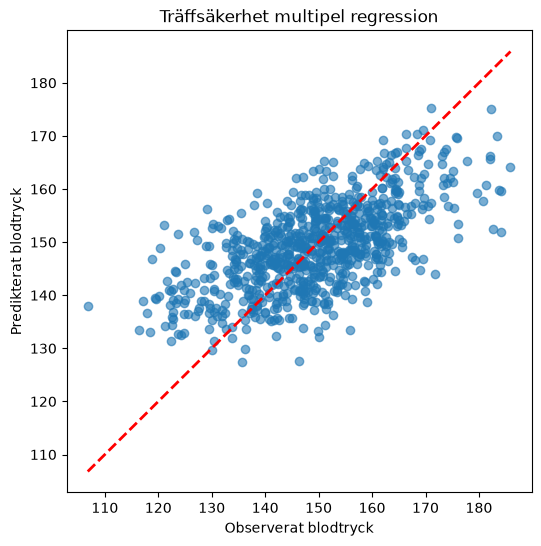

In [15]:
bp_investigator.plot_predictions()

Sammanfattande kommentarer till multipel regressionsanalys:

- Det R2 på 0,406 jag får fram innebär att modellen förklarar ungefär 40,6 % av variationen i systoliskt blodtryck genom variablerna: ålder, vikt, kolesterol och rökning.
- Det betyder därför att nästan 60% av variationen förklaras av helt andra faktorer än de jag hade med i modellen. Det kan vara faktorer som genetik, fysisk aktivitet, kostvanor, stress och så vidare.
- Samma sak egentligen bekräftas av figuren ovan. Den visar spridningen kring den streckade diagonalen, vilken representerar den teoretiskt perfekta matchningen mellan det observerade blodtrycket och det predikterade. Om punkterna hade varit mycket samlade kring diagonalen hade modellen matchat det befintliga sambandet väl.
- Nu finns en spridning vilket alltså motsvarar ett lägre R2-värde (närmare 0 än 1 i alla fall) och därmed en lägre träffsäkerhet.
- Koefficienten för smoker_num har ett minusvärde vilket i teorin skulle kunna motsvara att rökare har ett något lägre blodtryck (0.36 mmHg) än icke-rökare när övriga variabler är oförändrade. Detta låter ju inte så rimligt i verkligheten men jag tänker att det kan motsvaras av att medelvärdet i blodtryck mellan grupperna (rökare/icke-rökare) skiljde väldigt lite från början och att testet i sig hade låg power. Hypotesprövningen för just den alternativhypotesen gav också ett högt p-värde (ca 0.5), så det tycks hänga ihop hela vägen även om resultatet -0.36 först kan upplevas lite märkligt.
- Övriga koefficienter i den multipla regressionen följer ett mer förväntat mönster:
    * För varje levnadsår ökar blodtrycket med 0.52 mmHg 
    * För varje kilo i viktuppgång ökar blodtrycket med 0.17 mmHg
    * För en ökad enhet kolesterol ökar blodtrycket med 0.43 mmHg

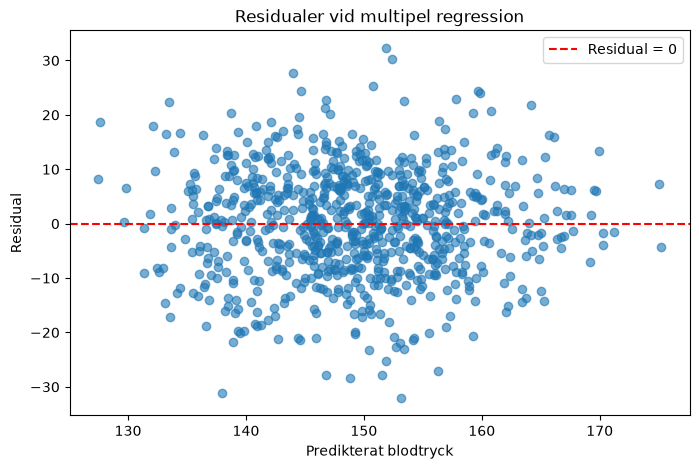

In [16]:
bp_investigator.plot_residuals()

Figuren över residualerna från den multipla regressionen synliggör det som modellen inte lyckas fånga (alltså 59%). Den föregående figuren visade blodtrycksvariationen som kan förklaras av ålder, vikt, kolesterol samt rökning och residualerna visar det som återstår. Det vill säga den del av verkligheten som egentligen bidrar till att förklara variation i blodtryck, men som i vårt ursprungliga material och med mina analyser inte har fått möjlighet att bli representerad överhuvudtaget. Om faktorerna ålder, vikt, kolesterol och rökning hade inneburit den fulla förklaringen till blodtryck hade alla enskilda observationer varit samlade kring den röda 0-linjen eftersom det inte hade funnits några residualvärden.